# COVID-19 Lockdowns and Urban Crime in Los Angeles

**Danish Ahsan Khan | MSc Data Analytics, Dublin Business School**

This notebook contains a completed rerun of the original dissertation analysis,
with its saved charts and model outputs. The study window is **1 January 2020
to 19 June 2023**, containing **750,936 recorded incidents** after filtering
the supplied 910,707-row CSV.

Models are fitted using a **10,000-record sample** from the training partition.
SMOTE expands that sample to 14,376 records. The separate test partition contains
225,281 original records. The models were not trained on all 750,936 incidents.

The original modelling method is retained. Preprocessing and SMOTE occur before
cross-validation, and ordinary SMOTE is applied to ordinal-encoded categories.
These are known validation limitations. This is retrospective classification,
and the descriptive trends do not establish causal effects of lockdowns.

The dataset-loading cell was adapted to accept a CSV in Colab or the repository's
`data/` directory. Model code and saved outputs are preserved. See
`docs/REVIEW_NOTES.md` and `results/run_summary.json` for details.


## 1. Imports

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from datetime import datetime

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

from imblearn.over_sampling import SMOTE


## 2. Load the dataset

Upload the CSV to Colab, or place it in the repository data folder. No automatic download is performed.

In [5]:
# Load LAPD crime data
from pathlib import Path

csv_filename = 'Crime_Data_from_2020_to_Present.csv'
data_candidates = [
    Path('/content') / csv_filename,
    Path.cwd() / 'data' / csv_filename,
    Path.cwd().parent / 'data' / csv_filename,
]
data_path = next((path for path in data_candidates if path.is_file()), None)
if data_path is None:
    raise FileNotFoundError(
        'Upload Crime_Data_from_2020_to_Present.csv to Colab, '
        'or place it in the repository data/ folder. See data/README.md.'
    )
data = pd.read_csv(data_path, low_memory=False)

print(data.shape)
data.head()


(910707, 28)


,DR_NO,Date Rptd,DATE OCC,TIME OCC,AREA,AREA NAME,Rpt Dist No,Part 1-2,Crm Cd,Crm Cd Desc,...,Status,Status Desc,Crm Cd 1,Crm Cd 2,Crm Cd 3,Crm Cd 4,LOCATION,Cross Street,LAT,LON
0,190326475,03/01/2020 12:00:00 AM,03/01/2020 12:00:00 AM,2130,7,Wilshire,784,1,510,VEHICLE - STOLEN,...,AA,Adult Arrest,510.0,998.0,NaN,NaN,1900 S LONGWOOD AV,NaN,34.0375,-118.3506
1,200106753,02/09/2020 12:00:00 AM,02/08/2020 12:00:00 AM,1800,1,Central,182,1,330,BURGLARY FROM VEHICLE,...,IC,Invest Cont,330.0,998.0,NaN,NaN,1000 S FLOWER ST,NaN,34.0444,-118.2628
2,200320258,11/11/2020 12:00:00 AM,11/04/2020 12:00:00 AM,1700,3,Southwest,356,1,480,BIKE - STOLEN,...,IC,Invest Cont,480.0,NaN,NaN,NaN,1400 W 37TH ST,NaN,34.0210,-118.3002
3,200907217,05/10/2023 12:00:00 AM,03/10/2020 12:00:00 AM,2037,9,Van Nuys,964,1,343,SHOPLIFTING-GRAND THEFT ($950.01 & OVER),...,IC,Invest Cont,343.0,NaN,NaN,NaN,14000 RIVERSIDE DR,NaN,34.1576,-118.4387
4,220614831,08/18/2022 12:00:00 AM,08/17/2020 12:00:00 AM,1200,6,Hollywood,666,2,354,THEFT OF IDENTITY,...,IC,Invest Cont,354.0,NaN,NaN,NaN,1900 TRANSIENT,NaN,34.0944,-118.3277


## 3. Clean records and select the study window

In [6]:
#Basic cleaning and date parsing

data = data.drop_duplicates()
print("After dropping duplicates:", data.shape)

date_occ_col = 'DATE OCC'
date_rpt_col = 'Date Rptd'

data[date_occ_col] = pd.to_datetime(data[date_occ_col], errors='coerce')
data[date_rpt_col] = pd.to_datetime(data[date_rpt_col], errors='coerce')

data = data.dropna(subset=[date_occ_col])
print("After dropping rows with invalid DATE OCC:", data.shape)

start_date = pd.Timestamp('2020-01-01')
end_date = pd.Timestamp('2023-06-19')

mask = (data[date_occ_col] >= start_date) & (data[date_occ_col] <= end_date)
data = data.loc[mask].copy()
print("After restricting to study period:", data.shape)


After dropping duplicates: (910707, 28)


/tmp/ipykernel_782/115205749.py:9: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data[date_occ_col] = pd.to_datetime(data[date_occ_col], errors='coerce')
/tmp/ipykernel_782/115205749.py:10: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data[date_rpt_col] = pd.to_datetime(data[date_rpt_col], errors='coerce')


After dropping rows with invalid DATE OCC: (910707, 28)
After restricting to study period: (750936, 28)


## 4. Derive incident features and study phases

Phase boundaries below are the original operational definitions used in this project.

In [7]:
# Temporal features, victim age processing, lockdown phases

data['Year'] = data[date_occ_col].dt.year
data['Month'] = data[date_occ_col].dt.month
data['DayOfWeek'] = data[date_occ_col].dt.dayofweek

if 'TIME OCC' in data.columns:
    data['Hour'] = (data['TIME OCC'] // 100).astype(int)
else:
    data['Hour'] = data[date_occ_col].dt.hour

if 'Vict Age' in data.columns:
    data.loc[(data['Vict Age'] < 0) | (data['Vict Age'] > 120), 'Vict Age'] = np.nan
else:
    data['Vict Age'] = np.nan

def get_age_category(age):
    if pd.isna(age):
        return 'Unknown'
    age = float(age)
    if age < 18:
        return 'Child'
    elif age < 30:
        return 'Young Adult'
    elif age < 50:
        return 'Adult'
    elif age < 65:
        return 'Middle-Aged'
    else:
        return 'Senior'

data['Vict_Age_Cat'] = data['Vict Age'].apply(get_age_category)

# Lockdown Phase (as per your Chapter 3)
def assign_lockdown_phase(dt):
    if dt < pd.Timestamp('2020-03-19'):
        return 'Pre-Lockdown'
    elif pd.Timestamp('2020-03-19') <= dt <= pd.Timestamp('2021-01-31'):
        return 'Lockdown'
    elif pd.Timestamp('2021-02-01') <= dt <= pd.Timestamp('2023-06-19'):
        return 'Post-Lockdown'
    else:
        return np.nan

data['Lockdown_Phase'] = data[date_occ_col].apply(assign_lockdown_phase)

print(data[['Year', 'Month', 'DayOfWeek', 'Hour', 'Vict Age', 'Vict_Age_Cat', 'Lockdown_Phase']].head())


   Year  Month  DayOfWeek  Hour  Vict Age Vict_Age_Cat Lockdown_Phase
0  2020      3          6    21       0.0        Child   Pre-Lockdown
1  2020      2          5    18      47.0        Adult   Pre-Lockdown
2  2020     11          2    17      19.0  Young Adult       Lockdown
3  2020      3          1    20      19.0  Young Adult   Pre-Lockdown
4  2020      8          0    12      28.0  Young Adult       Lockdown


## 5. Explore temporal patterns

Phase totals cover unequal durations. Compare incidents per calendar day in `results/phase_summary.csv`. June 2023 includes only 1–19 June, so its monthly total is incomplete.

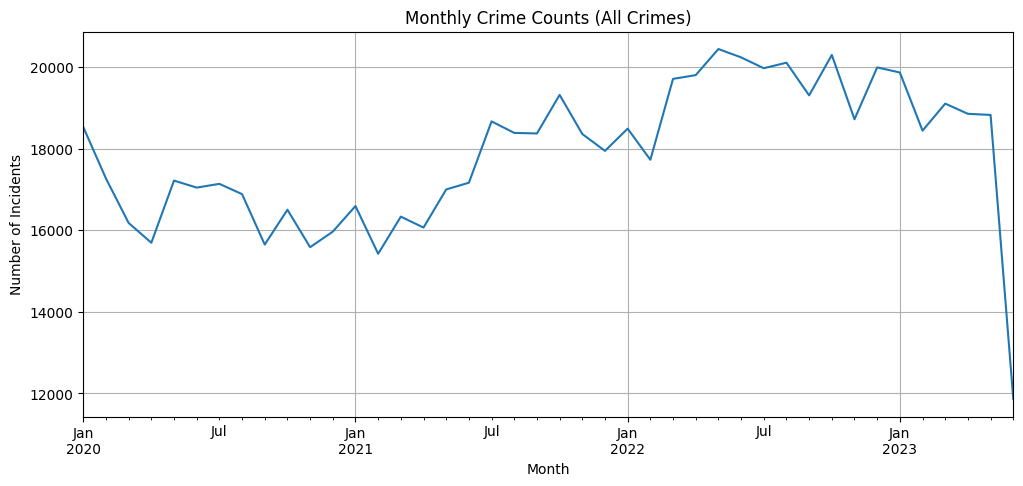

Crime counts by lockdown phase:
 Lockdown_Phase
Lockdown         170348
Post-Lockdown    534729
Pre-Lockdown      45859
Name: count, dtype: int64


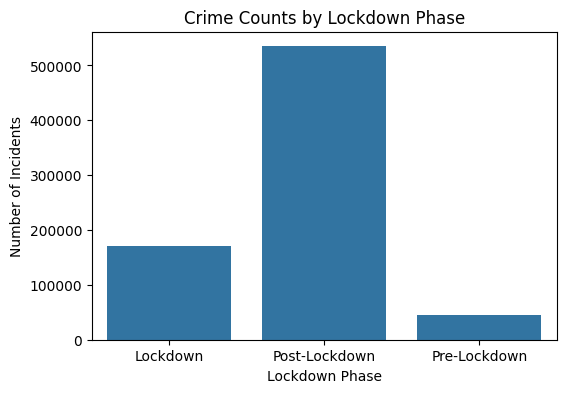

Top 5 crime categories across lockdown phases:
 Crm Cd Desc     BATTERY - SIMPLE ASSAULT  BURGLARY FROM VEHICLE  \
Lockdown_Phase                                                    
Lockdown                           13637                  10506   
Post-Lockdown                      41545                  32390   
Pre-Lockdown                        3861                   3332   

Crm Cd Desc     THEFT OF IDENTITY  \
Lockdown_Phase                      
Lockdown                     7465   
Post-Lockdown               40274   
Pre-Lockdown                 2281   

Crm Cd Desc     VANDALISM - FELONY ($400 & OVER, ALL CHURCH VANDALISMS)  \
Lockdown_Phase                                                            
Lockdown                                                    11246         
Post-Lockdown                                               31877         
Pre-Lockdown                                                 2763         

Crm Cd Desc     VEHICLE - STOLEN  
Lockdown_Phase     

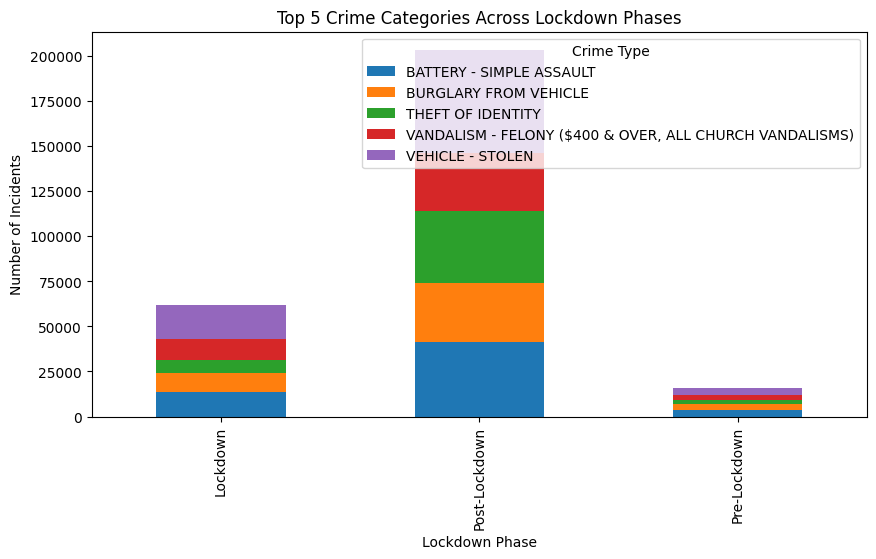

In [8]:
# Temporal trend analysis for RO1

# Overall monthly counts
monthly_counts = data.groupby([data[date_occ_col].dt.to_period('M')]).size()
monthly_counts.index = monthly_counts.index.to_timestamp()

plt.figure(figsize=(12, 5))
monthly_counts.plot()
plt.title('Monthly Crime Counts (All Crimes)')
plt.xlabel('Month')
plt.ylabel('Number of Incidents')
plt.grid(True)
plt.show()

# Crime counts by lockdown phase
phase_counts = data['Lockdown_Phase'].value_counts().sort_index()
print("Crime counts by lockdown phase:\n", phase_counts)

plt.figure(figsize=(6, 4))
sns.barplot(x=phase_counts.index, y=phase_counts.values)
plt.title('Crime Counts by Lockdown Phase')
plt.xlabel('Lockdown Phase')
plt.ylabel('Number of Incidents')
plt.show()

# top 5 crime categories and their distribution across phases
if 'Crm Cd Desc' in data.columns:
    top5_crimes = data['Crm Cd Desc'].value_counts().head(5).index
    top5_df = data[data['Crm Cd Desc'].isin(top5_crimes)]

    crosstab_phase_crime = pd.crosstab(top5_df['Lockdown_Phase'], top5_df['Crm Cd Desc'])

    print("Top 5 crime categories across lockdown phases:\n", crosstab_phase_crime)

    crosstab_phase_crime.plot(kind='bar', figsize=(10, 5), stacked=True)
    plt.title('Top 5 Crime Categories Across Lockdown Phases')
    plt.xlabel('Lockdown Phase')
    plt.ylabel('Number of Incidents')
    plt.legend(title='Crime Type')
    plt.show()


## 6. Define the binary classification target

The positive class follows the project-specific offence-description list below. It is not asserted to be a universal legal classification.

In [9]:
# CREATE BINARY TARGET: Violent vs Non-Violent Crime

violent_crimes = [
    'CRIMINAL HOMICIDE',
    'RAPE, FORCIBLE',
    'RAPE, ATTEMPTED',
    'SEXUAL PENETRATION W/FOREIGN OBJECT',
    'SODOMY/SEXUAL CONTACT B/W PENIS OF ONE PERS TO ANUS OTH',
    'SEX,UNLAWFUL(INC MUTUAL CONSENT, PENETRATION W/ FRGN OBJ',
    'ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT',
    'INTIMATE PARTNER - AGGRAVATED ASSAULT',
    'INTIMATE PARTNER - SIMPLE ASSAULT',
    'BATTERY - SIMPLE ASSAULT',
    'BATTERY POLICE (SIMPLE)',
    'BATTERY WITH SEXUAL CONTACT',
    'ASSAULT WITH DEADLY WEAPON ON POLICE OFFICER',
    'CHILD ABUSE (PHYSICAL) - AGGRAVATED ASSAULT',
    'CHILD ABUSE (PHYSICAL) - SIMPLE ASSAULT',
    'CHILD ANNOYING (17YRS & UNDER)',
    'CHILD NEGLECT (SEE 300 W.I.C.)',
    'LEWD/LASCIVIOUS ACTS WITH CHILD',
    'BRANDISH WEAPON',
    'SHOTS FIRED AT INHABITED DWELLING',
    'DISCHARGE FIREARMS/SHOTS FIRED',
    'SHOTS FIRED AT MOVING VEHICLE, TRAIN OR AIRCRAFT',
    'ROBBERY',
    'ATTEMPTED ROBBERY',
    'KIDNAPPING',
    'KIDNAPPING - GRAND ATTEMPT',
]

data['Violent'] = data['Crm Cd Desc'].apply(lambda x: 1 if x in violent_crimes else 0)

print("Violent crime distribution:")
print(data['Violent'].value_counts())


Violent crime distribution:
Violent
0    536877
1    214059
Name: count, dtype: int64


## 7. Select predictors and split records

In [10]:
feature_cols = [
    'Year', 'Month', 'DayOfWeek', 'Hour',
    'Vict Age', 'Vict_Age_Cat',
    'Vict Sex', 'Vict Descent',
    'Premis Desc',
    'AREA NAME',
    'Weapon Desc',
    'Lockdown_Phase'
]

In [11]:
#Prepare Data for Machine Learning (Binary Classification)

target_col = 'Violent'
data_ml = data.copy()

X = data_ml[feature_cols]
y = data_ml[target_col]

print("X shape:", X.shape)
print("Binary target distribution:\n", y.value_counts())

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)


X shape: (750936, 12)
Binary target distribution:
 Violent
0    536877
1    214059
Name: count, dtype: int64
Train shape: (525655, 12)
Test shape: (225281, 12)


In [12]:
# Identify numeric & categorical features

numeric_features = [col for col in feature_cols if X_train[col].dtype != 'object']
categorical_features = [col for col in feature_cols if X_train[col].dtype == 'object']

print("\nNumeric features:", numeric_features)
print("Categorical features:", categorical_features)


Numeric features: ['Year', 'Month', 'DayOfWeek', 'Hour', 'Vict Age']
Categorical features: ['Vict_Age_Cat', 'Vict Sex', 'Vict Descent', 'Premis Desc', 'AREA NAME', 'Weapon Desc', 'Lockdown_Phase']


## 8. Sample training records

In [13]:
sample_size = 10000

# Combine X_train and y_train into one DataFrame
train_df = pd.concat([X_train, y_train], axis=1)

# Random sampling
if len(train_df) > sample_size:
    train_df = train_df.sample(n=sample_size, random_state=42)
else:
    print("Training set is smaller than sample_size — using full training set.")

# Split back into X and y
X_train = train_df.drop(columns=[target_col])
y_train = train_df[target_col]

print("Training set AFTER sampling:", X_train.shape)
print("Class distribution AFTER sampling:\n", y_train.value_counts())


Training set AFTER sampling: (10000, 12)
Class distribution AFTER sampling:
 Violent
0    7188
1    2812
Name: count, dtype: int64


## 9. Original preprocessing and resampling

The next cells preserve the submitted workflow. Preprocessing and SMOTE are performed before cross-validation. Plain SMOTE can interpolate ordinal category codes. Treat reported validation results with these limitations.

In [14]:
from sklearn.impute import SimpleImputer

# 1. NUMERIC IMPUTATION
num_imputer = SimpleImputer(strategy='mean')
X_train_num = num_imputer.fit_transform(X_train[numeric_features])

# 2. CATEGORICAL ENCODING
cat_encoder = OrdinalEncoder(
    handle_unknown='use_encoded_value',
    unknown_value=-1
)
X_train_cat = cat_encoder.fit_transform(X_train[categorical_features].astype(str))

# Combine numeric + categorical for SMOTE
X_train_encoded = np.hstack([X_train_num, X_train_cat])

print("Encoded training shape:", X_train_encoded.shape)

Encoded training shape: (10000, 12)


In [15]:

print("Applying SMOTE on sampled training data...")

# --- Numeric features ---
X_train_num = X_train[numeric_features].copy()
num_imputer = SimpleImputer(strategy='mean')
X_train_num_imputed = num_imputer.fit_transform(X_train_num)

# --- Categorical features ---
cat_encoder_for_smote = OrdinalEncoder(
    handle_unknown='use_encoded_value',
    unknown_value=-1
)

X_train_cat = X_train[categorical_features].astype(str)
X_train_cat_encoded = cat_encoder_for_smote.fit_transform(X_train_cat)

# --- Combine numeric + categorical into single SMOTE-ready array ---
X_train_for_smote = np.hstack([X_train_num_imputed, X_train_cat_encoded])

print("Before SMOTE:", X_train_for_smote.shape)
print("Class distribution BEFORE SMOTE:\n", y_train.value_counts())

# --- Run SMOTE ---
smote = SMOTE(random_state=42, k_neighbors=1)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_for_smote, y_train)

print("After SMOTE:", X_train_resampled.shape)
print("Class distribution AFTER SMOTE:\n", y_train_resampled.value_counts())

print("SMOTE completed successfully.")


Applying SMOTE on sampled training data...
Before SMOTE: (10000, 12)
Class distribution BEFORE SMOTE:
 Violent
0    7188
1    2812
Name: count, dtype: int64
After SMOTE: (14376, 12)
Class distribution AFTER SMOTE:
 Violent
0    7188
1    7188
Name: count, dtype: int64
SMOTE completed successfully.


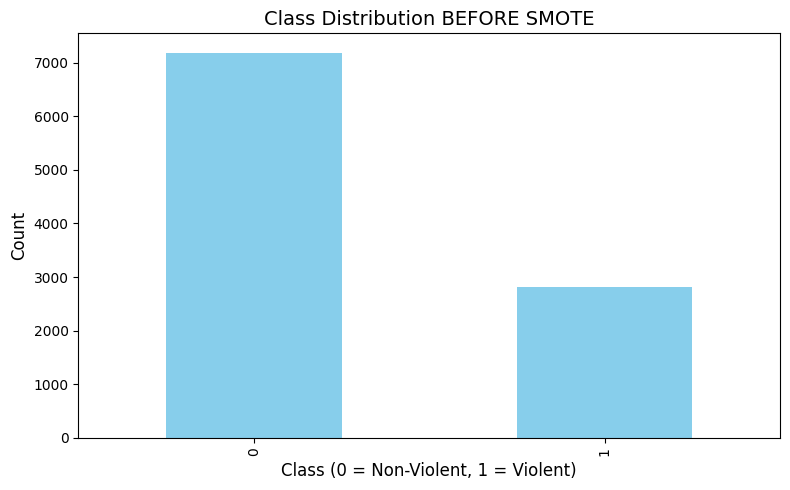

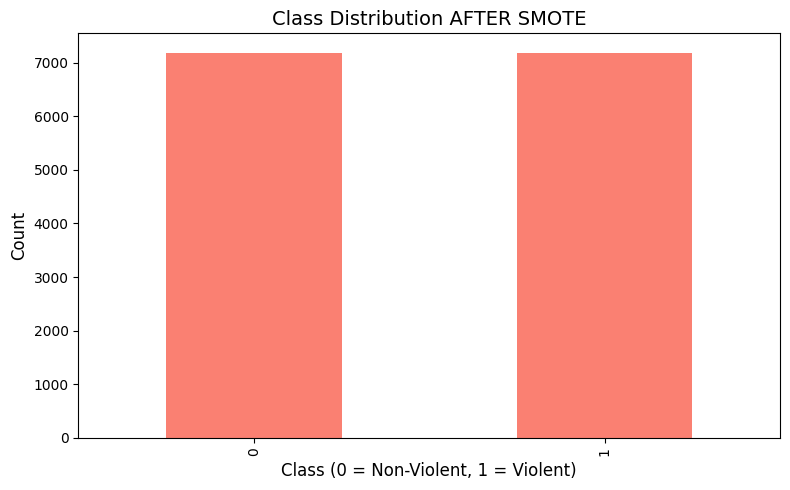

In [16]:
# BEFORE SMOTE
plt.figure(figsize=(8, 5))
y_train.value_counts().plot(kind='bar', color='skyblue')
plt.title('Class Distribution BEFORE SMOTE', fontsize=14)
plt.xlabel('Class (0 = Non-Violent, 1 = Violent)', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.tight_layout()
plt.show()

# AFTER SMOTE
plt.figure(figsize=(8, 5))
y_train_resampled.value_counts().plot(kind='bar', color='salmon')
plt.title('Class Distribution AFTER SMOTE', fontsize=14)
plt.xlabel('Class (0 = Non-Violent, 1 = Violent)', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.tight_layout()
plt.show()


In [19]:
# 4. SCALE FOR LR & SVM
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_resampled)

X_test_num = num_imputer.transform(X_test[numeric_features])

X_test_cat = cat_encoder.transform(X_test[categorical_features].astype(str))

X_test_encoded = np.hstack([X_test_num, X_test_cat])

X_test_scaled = scaler.transform(X_test_encoded)

## 10. Fit and evaluate classifiers

The test set is not resampled. These models classify existing incident records using recorded incident attributes.


=== Training Logistic Regression ===
Fitting 5 folds for each of 3 candidates, totalling 15 fits
Best parameters: {'C': 10.0, 'penalty': 'l2'}
Best CV Weighted F1: 0.9357352222803291
Accuracy: 0.9446735410442958
Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.96      0.96    161063
           1       0.91      0.89      0.90     64218

    accuracy                           0.94    225281
   macro avg       0.93      0.93      0.93    225281
weighted avg       0.94      0.94      0.94    225281



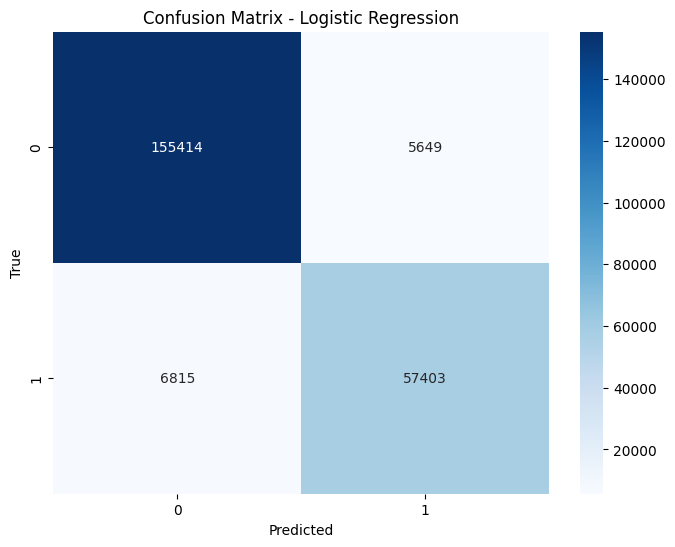

In [20]:
print("\n=== Training Logistic Regression ===")

# Logistic Regression model
lr = LogisticRegression(max_iter=500, n_jobs=-1)

# Parameter grid
params_lr = {
    'C': [0.1, 1.0, 10.0],
    'penalty': ['l2']
}

# GridSearch with scaled + SMOTE-resampled data
grid_lr = GridSearchCV(
    estimator=lr,
    param_grid=params_lr,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='f1_weighted',
    n_jobs=-1,
    verbose=1
)

# FIT using SMOTE-resampled and scaled data
grid_lr.fit(X_train_scaled, y_train_resampled)

print("Best parameters:", grid_lr.best_params_)
print("Best CV Weighted F1:", grid_lr.best_score_)

# Best model
best_lr = grid_lr.best_estimator_

# Predict on scaled TEST set
y_pred_lr = best_lr.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Classification Report:\n", classification_report(y_test, y_pred_lr))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()



=== Training Random Forest ===
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best parameters: {'max_depth': 20, 'min_samples_split': 5, 'n_estimators': 200}
Best CV Weighted F1: 0.9709814571468052
Accuracy: 0.9562901443086634
Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.95      0.97    161063
           1       0.89      0.97      0.93     64218

    accuracy                           0.96    225281
   macro avg       0.94      0.96      0.95    225281
weighted avg       0.96      0.96      0.96    225281



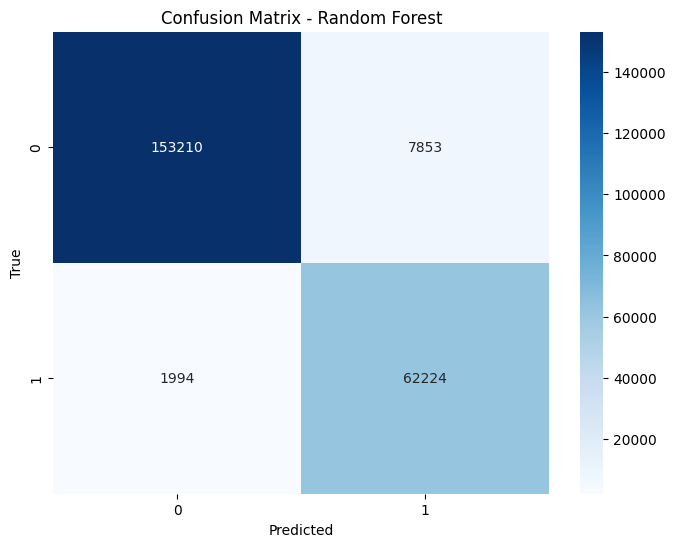

In [21]:
print("\n=== Training Random Forest ===")

# Base Random Forest model
rf = RandomForestClassifier(random_state=42, n_jobs=-1)

# Parameter grid
params_rf = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}

# GridSearchCV setup
grid_rf = GridSearchCV(
    estimator=rf,
    param_grid=params_rf,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='f1_weighted',
    n_jobs=-1,
    verbose=1
)

# FIT — use SMOTE-resampled encoded training data
grid_rf.fit(X_train_resampled, y_train_resampled)

print("Best parameters:", grid_rf.best_params_)
print("Best CV Weighted F1:", grid_rf.best_score_)

# Best model
best_rf = grid_rf.best_estimator_

# Predict on ENCODED (not scaled) TEST DATA
y_pred_rf = best_rf.predict(X_test_encoded)

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Classification Report:\n", classification_report(y_test, y_pred_rf))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()



=== Training SVM ===
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best parameters: {'C': 1.0, 'gamma': 'scale', 'kernel': 'rbf'}
Best CV Weighted F1: 0.9531798106366643
Accuracy: 0.9461605727957528
Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.96      0.96    161063
           1       0.91      0.90      0.91     64218

    accuracy                           0.95    225281
   macro avg       0.93      0.93      0.93    225281
weighted avg       0.95      0.95      0.95    225281



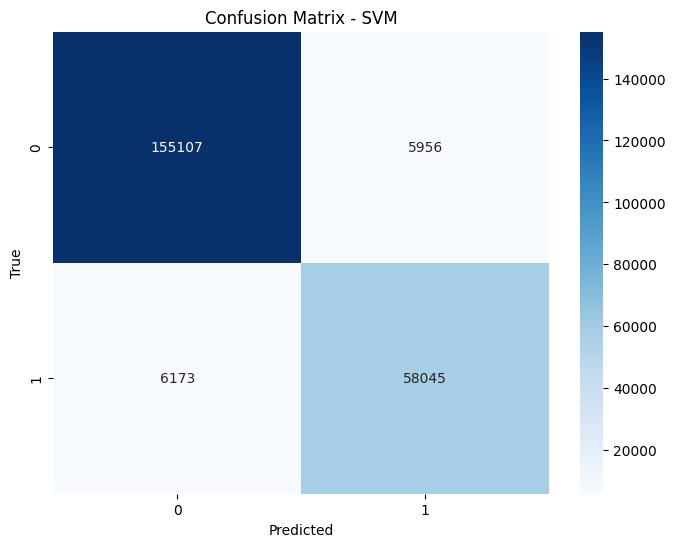

In [22]:
print("\n=== Training SVM ===")

# Base SVM model (kernel will be tuned via GridSearch)
svm = SVC()

# Parameter grid
params_svm = {
    'C': [0.5, 1.0],
    'kernel': ['rbf'],
    'gamma': ['scale', 'auto']
}

# GridSearchCV
grid_svm = GridSearchCV(
    estimator=svm,
    param_grid=params_svm,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='f1_weighted',
    n_jobs=-1,
    verbose=1
)

# Fit on **scaled SMOTE-resampled training data**
grid_svm.fit(X_train_scaled, y_train_resampled)

print("Best parameters:", grid_svm.best_params_)
print("Best CV Weighted F1:", grid_svm.best_score_)

# Best model
best_svm = grid_svm.best_estimator_

# Predict on **scaled test data**
y_pred_svm = best_svm.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print("Classification Report:\n", classification_report(y_test, y_pred_svm))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_svm)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - SVM")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()



=== Training XGBoost ===
Fitting 5 folds for each of 8 candidates, totalling 40 fits


/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [02:47:09] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Best parameters: {'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 200}
Best CV Weighted F1: 0.9710529846130918
Accuracy: 0.9569382238182537
Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.95      0.97    161063
           1       0.89      0.97      0.93     64218

    accuracy                           0.96    225281
   macro avg       0.94      0.96      0.95    225281
weighted avg       0.96      0.96      0.96    225281



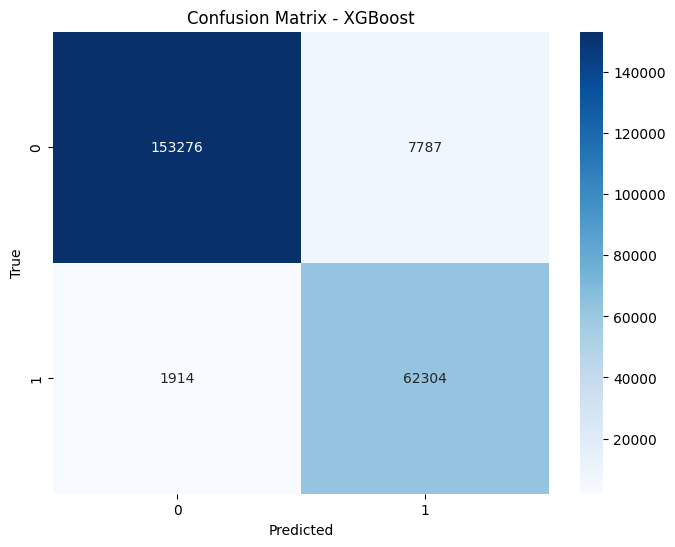

In [23]:
print("\n=== Training XGBoost ===")

# Base XGBoost model
xgb = XGBClassifier(
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1,
    use_label_encoder=False
)

# Parameter grid
params_xgb = {
    'n_estimators': [100, 200],
    'max_depth': [4, 6],
    'learning_rate': [0.05, 0.1]
}

# GridSearchCV
grid_xgb = GridSearchCV(
    estimator=xgb,
    param_grid=params_xgb,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='f1_weighted',
    n_jobs=-1,
    verbose=1
)

# FIT — use SMOTE-resampled encoded training data
grid_xgb.fit(X_train_resampled, y_train_resampled)

print("Best parameters:", grid_xgb.best_params_)
print("Best CV Weighted F1:", grid_xgb.best_score_)

# Best estimator
best_xgb = grid_xgb.best_estimator_

# Predict on encoded test set
y_pred_xgb = best_xgb.predict(X_test_encoded)

print("Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("Classification Report:\n", classification_report(y_test, y_pred_xgb))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_xgb)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix - XGBoost")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()


## 11. Compare this run

Scores below describe this specific split and original method. Small score differences do not establish statistically significant superiority.

In [24]:
from sklearn.metrics import f1_score

results_summary = [
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred_lr),
        "F1_Weighted": f1_score(y_test, y_pred_lr, average='weighted')
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, y_pred_rf),
        "F1_Weighted": f1_score(y_test, y_pred_rf, average='weighted')
    },
    {
        "Model": "SVM",
        "Accuracy": accuracy_score(y_test, y_pred_svm),
        "F1_Weighted": f1_score(y_test, y_pred_svm, average='weighted')
    },
    {
        "Model": "XGBoost",
        "Accuracy": accuracy_score(y_test, y_pred_xgb),
        "F1_Weighted": f1_score(y_test, y_pred_xgb, average='weighted')
    },
]

results_df = pd.DataFrame(results_summary)

# Sort by accuracy or F1 score
print("\n=== MODEL PERFORMANCE SUMMARY ===")
print(results_df.sort_values("F1_Weighted", ascending=False).reset_index(drop=True))



=== MODEL PERFORMANCE SUMMARY ===
                 Model  Accuracy  F1_Weighted
0              XGBoost  0.956938     0.957480
1        Random Forest  0.956290     0.956839
2                  SVM  0.946161     0.946133
3  Logistic Regression  0.944674     0.944520


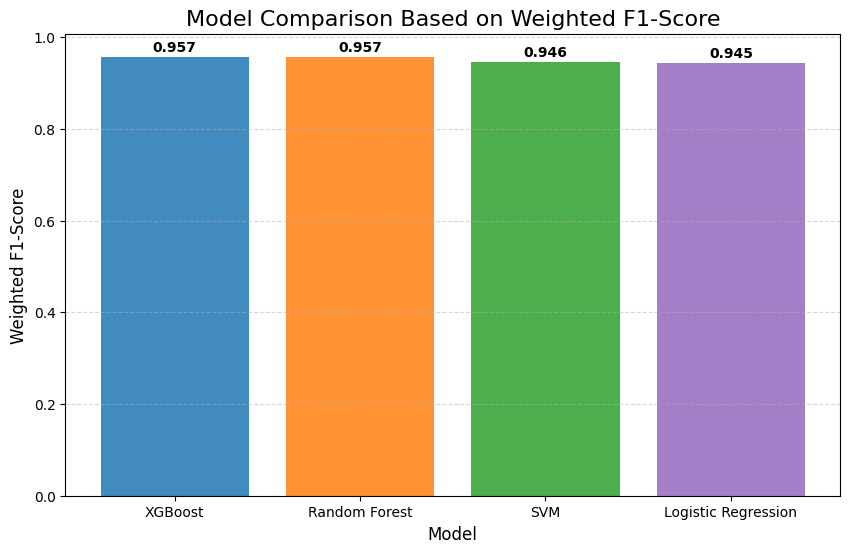

In [25]:
plt.figure(figsize=(10, 6))

plot_df = results_df.sort_values("F1_Weighted", ascending=False)

bars = plt.bar(
    plot_df["Model"],
    plot_df["F1_Weighted"],
    color=["#1f77b4", "#ff7f0e", "#2ca02c", "#9467bd"],
    alpha=0.85
)

# Add data labels
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.005,
        f"{height:.3f}",
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

plt.title("Model Comparison Based on Weighted F1-Score", fontsize=16)
plt.xlabel("Model", fontsize=12)
plt.ylabel("Weighted F1-Score", fontsize=12)
plt.ylim(0, max(plot_df["F1_Weighted"]) + 0.05)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()
